# 2. Analyze a NeXus file, as a Python library

Replays a completed event NeXus file through the analyzer: diamond run NOM_243708, corrected with
the empty-can background and vanadium normalization from the preparer.

NeXus replay goes bank by bank: NOMAD files hold about 100 `bankN_events` groups, each covering
the whole run. Elapsed time and proton charge are therefore attributed from the run totals in
proportion to the events processed so far, not read pulse by pulse as on the ADARA path.

**Before you start:** run `01_preparer_cli.ipynb` or `01_preparer_python.ipynb` once. They write the
pixel geometry, background and normalization CSVs into `notebooks/output/` that every analyze
notebook reads.

**Runtime:** about 4 minutes for NOM_243708's 232 million events. Adding NOM_243709 (2 billion
events) takes roughly ten times as long.

## Setup

Every path below is relative to the repository root, so the commands are the same ones you would
type in a terminal from there.

In [1]:
import os
import sys
from pathlib import Path

# Run from the repository root so every path matches the README and the terminal commands.
REPO_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "pyproject.toml").exists())
os.chdir(REPO_ROOT)
# Shell cells resolve `live_stream_analysis` and `python` from this kernel's environment.
os.environ["PATH"] = f"{Path(sys.executable).parent}{os.pathsep}{os.environ['PATH']}"

OUTPUT_DIR = Path("notebooks/output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Working directory: {Path.cwd()}")
# True: show the live plot inside this notebook. False: open it in a browser tab instead.
LIVE_PLOT_INLINE = True

for prepared in ["pixel_geometry_calibrated.csv", "background.csv", "normalization.csv", "diamond_reflections.csv"]:
    if not (OUTPUT_DIR / prepared).exists():
        raise FileNotFoundError(f"{OUTPUT_DIR / prepared} is missing; run a 01_preparer notebook first")

Working directory: /home/ntm/projects/illumine/live_stream_analysis


## Run it

`start_analysis` takes the CLI options as keywords: the flag name with underscores instead of
dashes, a list for a repeatable flag such as `nexus_file`, a `(host, port)` pair for
`adara_stream`, and `True` for an on/off flag. The CLI's own parser validates them, so the defaults
and error messages are identical to the terminal, and a typo raises before anything starts.

It returns an `AnalysisRun` handle:

| Method | Does |
| --- | --- |
| `show()` | Embed the live plot in the cell output |
| `plot_state()` | The plot's current data, including a `status` summary |
| `wait()` | Block until the analysis finishes |
| `wait_for_log(text)` | Block until a log line appears, such as a completed run on a live stream |
| `log()` | The last lines of the analyzer's output |
| `stop()` | Interrupt the analyzer and shut down the plot |
| `command` | The equivalent shell command |

`live_plot="inline"` (the default) serves the plot for `show()`; `"browser"` also opens a tab; `None`
disables it.

| Option | Why |
| --- | --- |
| `--nexus-file` | The sample. Repeat it to combine runs, e.g. add `--nexus-file nexus_files/diamond/NOM_243709.nxs.h5` |
| `--live-plot-refresh-every 10` | Refresh every 10 chunks of 250,000 events |
| `--histogram-pixel-geometry-csv` | Per-pixel TOF→Q constants from the preparer, here with the 2026-06-09 calibration applied |
| `--histogram-q-min/-max/-bin-size` | 0–40 1/Å in 0.02 bins, the same binning the preparer used for background and vanadium |
| `--tof-tick-us 1.0` | NeXus `event_time_offset` is in µs. With this setting the calibrated geometry puts NOM_243708's diamond reflections within ~0.001 1/Å of their literature positions |
| `--background-subtraction`, `--normalization` | The empty-can and vanadium CSVs from the preparer |
| `--normalize-by proton-charge` | The default, spelled out: sample, background and vanadium are each divided by their own charge |
| `--histogram-output-csv` | The corrected I(Q) |
| `--statistics-output-csv`, `--statistics-q-min/-max` | The error-decay series, over the 2–18 1/Å range where diamond has its strong reflections |
| `--live-plot-*` | Browser plot on a fixed port, kept open after the analysis, without opening a browser tab |

In [2]:
from live_stream_analysis.notebook import start_analysis

run = start_analysis(
    live_plot="inline" if LIVE_PLOT_INLINE else "browser",
    log_file=OUTPUT_DIR / "nexus_python.log",
    nexus_file=[Path("nexus_files/diamond/NOM_243708.nxs.h5")],
    histogram_pixel_geometry_csv=OUTPUT_DIR / "pixel_geometry_calibrated.csv",
    histogram_q_min=0.0,
    histogram_q_max=40.0,
    histogram_q_bin_size=0.02,
    tof_tick_us=1.0,
    background_subtraction=OUTPUT_DIR / "background.csv",
    normalization=OUTPUT_DIR / "normalization.csv",
    normalize_by="proton-charge",
    histogram_output_csv=OUTPUT_DIR / "nexus_python_iq.csv",
    statistics_output_csv=OUTPUT_DIR / "nexus_python_statistics.csv",
    statistics_q_min=2.0,
    statistics_q_max=18.0,
    live_plot_refresh_every=10,
    event_log_interval=10_000_000,
)
print(run.command)  # the equivalent terminal command
run

live_stream_analysis analyze --nexus-file nexus_files/diamond/NOM_243708.nxs.h5 --histogram-pixel-geometry-csv notebooks/output/pixel_geometry_calibrated.csv --histogram-q-min 0.0 --histogram-q-max 40.0 --histogram-q-bin-size 0.02 --tof-tick-us 1.0 --background-subtraction notebooks/output/background.csv --normalization notebooks/output/normalization.csv --normalize-by proton-charge --histogram-output-csv notebooks/output/nexus_python_iq.csv --statistics-output-csv notebooks/output/nexus_python_statistics.csv --statistics-q-min 2.0 --statistics-q-max 18.0 --live-plot-refresh-every 10 --event-log-interval 10000000 --live-plot-mode browser --live-plot-keep-open --live-plot-no-open-browser --live-plot-port 39681


<AnalysisRun running url=http://127.0.0.1:39681/ log=/home/ntm/projects/illumine/live_stream_analysis/notebooks/output/nexus_python.log>

### How the live plot gets into the notebook

`live_plot_mode browser` makes the analyzer serve its plot page from a small HTTP server on its own
thread, and the page polls that server twice a second. Because the page talks to the analyzer and
not to the notebook kernel, it can sit in a cell output and keep updating while the kernel does
other things. The analysis therefore runs as a background process, and `show()` embeds the page
once the server is up.

`--live-plot-keep-open` keeps the page up after the analysis finishes, showing **Analysis complete**,
until you call `stop()`. Set `LIVE_PLOT_INLINE = False` above to open the same page in a browser
tab instead. The page loads Chart.js from a CDN, so it needs internet access.

In [3]:
if LIVE_PLOT_INLINE:
    run.show()
else:
    import webbrowser

    run.wait_for_plot()
    webbrowser.open(run.url)
    print(f"Live plot opened at {run.url}")

In [4]:
import time

# Re-run this cell any time for a progress snapshot; the analysis keeps going in the background.
deadline = time.monotonic() + 120
while run.plot_state()["status"]["update_count"] == 0 and time.monotonic() < deadline:
    time.sleep(2)
status = run.plot_state()["status"]
print(
    f"updates={status['update_count']}  elapsed={status['elapsed_seconds']:.1f} s  "
    f"charge={status['proton_charge_pc']:.3g} pC  mean sigma/I={status['mean_relative_uncertainty']:.4f}"
)

updates=1  elapsed=0.2 s  charge=2.45e+08 pC  mean sigma/I=0.1122


## Wait for it to finish

The live plot keeps updating above while this cell waits.

In [5]:
run.wait()
print(run.log(22))

Processing NeXus chunks: 164/993 ( 16.5%) [NOM_243708.nxs.h5]2026-10-21 15:16:55,047 INFO live_stream_analysis.analyzer.nexus: Histogrammed 20000000 events after 165 NeXus chunks (40918929 total source events)
Processing NeXus chunks: 247/993 ( 24.9%) [NOM_243708.nxs.h5]2026-10-21 15:17:18,281 INFO live_stream_analysis.analyzer.nexus: Histogrammed 30000000 events after 248 NeXus chunks (57148883 total source events)
Processing NeXus chunks: 344/993 ( 34.6%) [NOM_243708.nxs.h5]2026-10-21 15:17:38,279 INFO live_stream_analysis.analyzer.nexus: Histogrammed 40000000 events after 345 NeXus chunks (80539948 total source events)
Processing NeXus chunks: 425/993 ( 42.8%) [NOM_243708.nxs.h5]2026-10-21 15:17:57,715 INFO live_stream_analysis.analyzer.nexus: Histogrammed 50000000 events after 426 NeXus chunks (103297386 total source events)
Processing NeXus chunks: 513/993 ( 51.7%) [NOM_243708.nxs.h5]2026-10-21 15:18:21,609 INFO live_stream_analysis.analyzer.nexus: Histogrammed 60000000 events aft

## Results

The corrected I(Q) is background-subtracted and vanadium-normalized, with sample, background and
vanadium each divided by their own proton charge. Dashed lines mark the expected diamond
reflections (a = 3.56712 Å), as an absolute check on the Q axis. The right panel is the error-decay
series the INTERSECT forecasting service consumes: for counting statistics, the mean σ/I(Q) should
fall as 1/√charge.

Here the decay falls faster than 1/√charge, and that is expected for NeXus. The file is replayed bank by bank, with charge attributed in proportion to events, so the early samples cover only a few detector banks. Use the ADARA notebooks for a decay curve measured in time order.

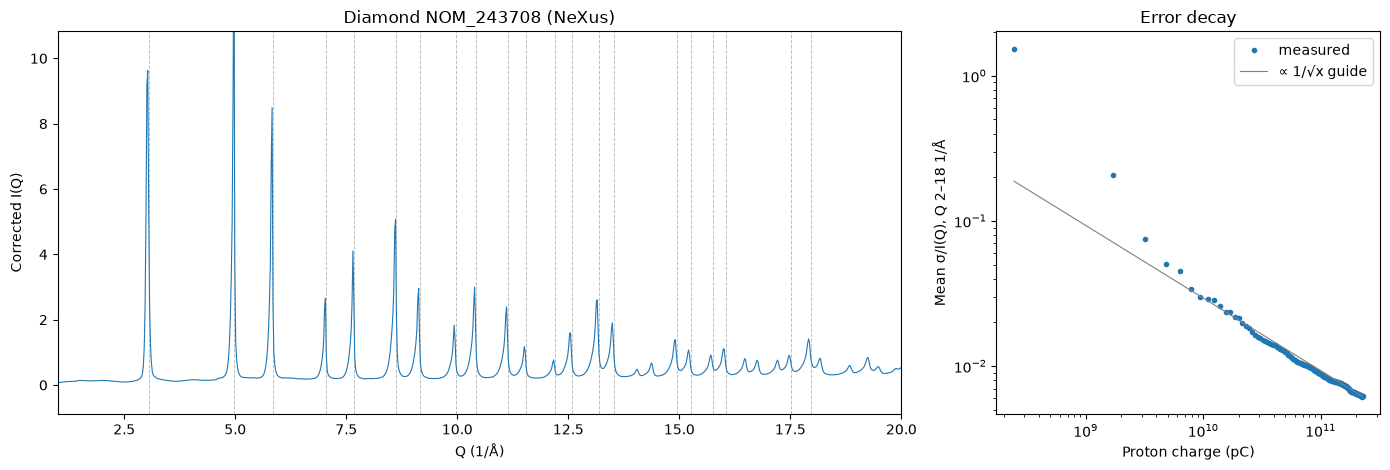

154 decay samples; final mean sigma/I = 0.0062 at 2.271e+11 (Proton charge (pC))


In [6]:
import matplotlib.pyplot as plt
import numpy as np

from live_stream_analysis.notebook import read_csv

iq = read_csv(OUTPUT_DIR / "nexus_python_iq.csv")
statistics = read_csv(OUTPUT_DIR / "nexus_python_statistics.csv")
reflections = read_csv(OUTPUT_DIR / "diamond_reflections.csv")

q, intensity, error = iq["Q value"], iq["I(Q)"], iq["Error I(Q)"]
window = (q > 1.0) & (q < 20.0)
low, high = np.nanpercentile(intensity[window], [0.5, 99.9])

fig, (ax_iq, ax_decay) = plt.subplots(1, 2, figsize=(14, 4.8), width_ratios=[2.2, 1])
for q_peak in reflections["Q (1/A)"][reflections["rel intensity"] > 0.5]:
    ax_iq.axvline(q_peak, color="0.75", linestyle="--", linewidth=0.7, zorder=0)
ax_iq.fill_between(q, intensity - error, intensity + error, alpha=0.3, linewidth=0)
ax_iq.plot(q, intensity, linewidth=0.8)
ax_iq.set(
    xlim=(1.0, 20.0),
    ylim=(low - 0.1 * (high - low), high + 0.1 * (high - low)),
    xlabel="Q (1/Å)",
    ylabel="Corrected I(Q)",
    title="Diamond NOM_243708 (NeXus)",
)

charge = statistics["Proton charge (pC)"]
x_values, x_label = (charge, "Proton charge (pC)") if np.nanmax(charge) > 0 else (statistics["Elapsed time (s)"], "Elapsed time (s)")
sigma = statistics["Mean sigma/I(Q)"]
measured = x_values > 0  # the first sample can land before any charge or time has accrued
x_values, sigma = x_values[measured], sigma[measured]
ax_decay.loglog(x_values, sigma, marker=".", linestyle="none", label="measured")
# Anchored on the last, best-determined sample; the earliest ones carry almost no counts.
ax_decay.loglog(x_values, sigma[-1] * np.sqrt(x_values[-1] / x_values), color="0.5", linewidth=0.8, label="∝ 1/√x guide")
ax_decay.set(xlabel=x_label, ylabel="Mean σ/I(Q), Q 2–18 1/Å", title="Error decay")
ax_decay.legend()
fig.tight_layout()
plt.show()

print(f"{len(sigma)} decay samples; final mean sigma/I = {sigma[-1]:.4f} at {x_values[-1]:.4g} ({x_label})")

## Stop

`stop()` interrupts the analyzer as Ctrl-C would and shuts down the plot server. Everything above
was already written to `notebooks/output/`, so nothing is lost.

In [7]:
print(f"Analyzer exit code {run.stop()} (130 means it was interrupted, as intended)")

Analyzer exit code 130 (130 means it was interrupted, as intended)
